In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
project_root = Path.cwd().parent

kpi_path = (
    project_root
    / "data"
    / "processed"
    / "SaaS_Monthly_KPI_Summary.csv"
)

monthly_kpis = pd.read_csv(kpi_path)

print("Dataset shape:", monthly_kpis.shape)
print("\nAvailable columns:")
print(monthly_kpis.columns.tolist())

display(monthly_kpis.head())

Dataset shape: (30, 25)

Available columns:
['Month', 'Total_MRR_USD', 'Previous_Month_MRR', 'MRR_Change_USD', 'MRR_Growth_Pct', 'New_MRR', 'Expansion_MRR', 'Contraction_MRR', 'Churn_MRR', 'Reactivation_MRR', 'Net_MRR_Change', 'Opening_Paid_Subscriptions', 'Churn_Records', 'Customers_With_Churn_Event', 'Subscription_Churn_Rate_Pct', 'Retained_Subscriptions', 'Closing_Paid_Subscriptions', 'Subscription_Retention_Rate_Pct', 'Opening_Paid_Customers', 'Retained_Customers', 'Closing_Paid_Customers', 'Customer_Retention_Rate_Pct', 'Opening_MRR_USD', 'GRR_Pct', 'NRR_Pct']


,Month,Total_MRR_USD,Previous_Month_MRR,MRR_Change_USD,MRR_Growth_Pct,New_MRR,Expansion_MRR,Contraction_MRR,Churn_MRR,Reactivation_MRR,Net_MRR_Change,Opening_Paid_Subscriptions,Churn_Records,Customers_With_Churn_Event,Subscription_Churn_Rate_Pct,Retained_Subscriptions,Closing_Paid_Subscriptions,Subscription_Retention_Rate_Pct,Opening_Paid_Customers,Retained_Customers,Closing_Paid_Customers,Customer_Retention_Rate_Pct,Opening_MRR_USD,GRR_Pct,NRR_Pct
0,2024-01-01,145853.24,NaN,NaN,NaN,145853.24,0.00,-0.0,-0.00,0.0,145853.24,0,0,0,NaN,0,464,NaN,0,0,464,NaN,0.00,NaN,NaN
1,2024-02-01,151051.80,145853.24,5198.56,3.56,6830.65,1276.20,615.4,2292.89,0.0,5198.56,464,13,13,2.80,451,468,97.20,464,451,468,97.20,145853.24,98.01,98.88
2,2024-03-01,155769.21,151051.80,4717.41,3.12,2047.34,5748.80,279.4,2799.33,0.0,4717.41,468,14,14,2.99,454,463,97.01,468,454,463,97.01,151051.80,97.96,101.77
3,2024-04-01,163530.40,155769.21,7761.19,4.98,5965.74,4819.65,375.2,2649.00,0.0,7761.19,463,12,12,2.59,451,465,97.41,463,451,465,97.41,155769.21,98.06,101.15
4,2024-05-01,171524.29,163530.40,7993.89,4.89,3828.17,6698.50,204.0,2328.78,0.0,7993.89,465,12,12,2.58,453,474,97.42,465,453,474,97.42,163530.40,98.45,102.55


In [3]:
print("Total rows:", len(monthly_kpis))

print(
    "Duplicate rows:",
    monthly_kpis.duplicated().sum()
)

print("\nMissing values:")
display(monthly_kpis.isna().sum())

print("\nData types:")
display(monthly_kpis.dtypes)

Total rows: 30
Duplicate rows: 0

Missing values:


Month                              0
Total_MRR_USD                      0
Previous_Month_MRR                 1
MRR_Change_USD                     1
MRR_Growth_Pct                     1
New_MRR                            0
Expansion_MRR                      0
Contraction_MRR                    0
Churn_MRR                          0
Reactivation_MRR                   0
Net_MRR_Change                     0
Opening_Paid_Subscriptions         0
Churn_Records                      0
Customers_With_Churn_Event         0
Subscription_Churn_Rate_Pct        1
Retained_Subscriptions             0
Closing_Paid_Subscriptions         0
Subscription_Retention_Rate_Pct    1
Opening_Paid_Customers             0
Retained_Customers                 0
Closing_Paid_Customers             0
Customer_Retention_Rate_Pct        1
Opening_MRR_USD                    0
GRR_Pct                            1
NRR_Pct                            1
dtype: int64


Data types:


Month                                  str
Total_MRR_USD                      float64
Previous_Month_MRR                 float64
MRR_Change_USD                     float64
MRR_Growth_Pct                     float64
New_MRR                            float64
Expansion_MRR                      float64
Contraction_MRR                    float64
Churn_MRR                          float64
Reactivation_MRR                   float64
Net_MRR_Change                     float64
Opening_Paid_Subscriptions           int64
Churn_Records                        int64
Customers_With_Churn_Event           int64
Subscription_Churn_Rate_Pct        float64
Retained_Subscriptions               int64
Closing_Paid_Subscriptions           int64
Subscription_Retention_Rate_Pct    float64
Opening_Paid_Customers               int64
Retained_Customers                   int64
Closing_Paid_Customers               int64
Customer_Retention_Rate_Pct        float64
Opening_MRR_USD                    float64
GRR_Pct    

In [4]:
revenue_keywords = [
    "mrr",
    "revenue",
    "growth",
    "expansion",
    "contraction",
    "churn",
    "reactivation"
]

revenue_columns = [
    col
    for col in monthly_kpis.columns
    if any(
        keyword in col.lower()
        for keyword in revenue_keywords
    )
]

print("Revenue-related columns:")

for col in revenue_columns:
    print("-", col)

Revenue-related columns:
- Total_MRR_USD
- Previous_Month_MRR
- MRR_Change_USD
- MRR_Growth_Pct
- New_MRR
- Expansion_MRR
- Contraction_MRR
- Churn_MRR
- Reactivation_MRR
- Net_MRR_Change
- Churn_Records
- Customers_With_Churn_Event
- Subscription_Churn_Rate_Pct
- Opening_MRR_USD


In [5]:
month_columns = [
    col
    for col in monthly_kpis.columns
    if "month" in col.lower()
    or "period" in col.lower()
    or "date" in col.lower()
]

print("Possible reporting month columns:")
print(month_columns)

if len(month_columns) == 1:
    month_col = month_columns[0]

    parsed_months = pd.to_datetime(
        monthly_kpis[month_col],
        errors="coerce"
    )

    print(
        "Invalid reporting dates:",
        parsed_months.isna().sum()
    )

    print(
        "Duplicate reporting months:",
        parsed_months.duplicated().sum()
    )

    print("First month:", parsed_months.min())
    print("Last month:", parsed_months.max())

else:
    print(
        "Review reporting month columns before "
        "selecting the correct one."
    )

Possible reporting month columns:
['Month', 'Previous_Month_MRR']
Review reporting month columns before selecting the correct one.


In [6]:
# Step 6.2.2 - Inspect reporting and MRR columns

print("Available columns:")
print(monthly_kpis.columns.tolist())

print("\nMRR-related columns:")
print([
    col for col in monthly_kpis.columns
    if "mrr" in col.lower()
])

print("\nPossible month columns:")
print([
    col for col in monthly_kpis.columns
    if "month" in col.lower()
    or "period" in col.lower()
])

display(monthly_kpis.head(3))

Available columns:
['Month', 'Total_MRR_USD', 'Previous_Month_MRR', 'MRR_Change_USD', 'MRR_Growth_Pct', 'New_MRR', 'Expansion_MRR', 'Contraction_MRR', 'Churn_MRR', 'Reactivation_MRR', 'Net_MRR_Change', 'Opening_Paid_Subscriptions', 'Churn_Records', 'Customers_With_Churn_Event', 'Subscription_Churn_Rate_Pct', 'Retained_Subscriptions', 'Closing_Paid_Subscriptions', 'Subscription_Retention_Rate_Pct', 'Opening_Paid_Customers', 'Retained_Customers', 'Closing_Paid_Customers', 'Customer_Retention_Rate_Pct', 'Opening_MRR_USD', 'GRR_Pct', 'NRR_Pct']

MRR-related columns:
['Total_MRR_USD', 'Previous_Month_MRR', 'MRR_Change_USD', 'MRR_Growth_Pct', 'New_MRR', 'Expansion_MRR', 'Contraction_MRR', 'Churn_MRR', 'Reactivation_MRR', 'Net_MRR_Change', 'Opening_MRR_USD']

Possible month columns:
['Month', 'Previous_Month_MRR']


,Month,Total_MRR_USD,Previous_Month_MRR,MRR_Change_USD,MRR_Growth_Pct,New_MRR,Expansion_MRR,Contraction_MRR,Churn_MRR,Reactivation_MRR,Net_MRR_Change,Opening_Paid_Subscriptions,Churn_Records,Customers_With_Churn_Event,Subscription_Churn_Rate_Pct,Retained_Subscriptions,Closing_Paid_Subscriptions,Subscription_Retention_Rate_Pct,Opening_Paid_Customers,Retained_Customers,Closing_Paid_Customers,Customer_Retention_Rate_Pct,Opening_MRR_USD,GRR_Pct,NRR_Pct
0,2024-01-01,145853.24,NaN,NaN,NaN,145853.24,0.0,-0.0,-0.00,0.0,145853.24,0,0,0,NaN,0,464,NaN,0,0,464,NaN,0.00,NaN,NaN
1,2024-02-01,151051.80,145853.24,5198.56,3.56,6830.65,1276.2,615.4,2292.89,0.0,5198.56,464,13,13,2.80,451,468,97.20,464,451,468,97.20,145853.24,98.01,98.88
2,2024-03-01,155769.21,151051.80,4717.41,3.12,2047.34,5748.8,279.4,2799.33,0.0,4717.41,468,14,14,2.99,454,463,97.01,468,454,463,97.01,151051.80,97.96,101.77


In [8]:
month_col = "Month"
mrr_col = "Total_MRR_USD"

required_columns = [month_col, mrr_col]

missing_columns = [
    col for col in required_columns
    if col not in monthly_kpis.columns
]

if missing_columns:
    print("Columns not found:", missing_columns)
else:
    print("Required columns found.")

Required columns found.


In [12]:
# ==================================================
# Step 6.2.2 - Part C
# Select Reporting Month and MRR Columns
# ==================================================

# Correct column names from your dataset
month_col = "Month"
mrr_col = "Total_MRR_USD"

# Required columns
required_columns = [month_col, mrr_col]

# Check missing columns
missing_columns = [
    col for col in required_columns
    if col not in monthly_kpis.columns
]

# Validation
if missing_columns:
    print("Columns not found:", missing_columns)
    print("Available columns:", monthly_kpis.columns.tolist())
else:
    print("Required columns found.")
    print("Reporting Month Column:", month_col)
    print("Monthly MRR Column:", mrr_col)

    # Preview selected columns
    display(monthly_kpis[[month_col, mrr_col]].head())

Required columns found.
Reporting Month Column: Month
Monthly MRR Column: Total_MRR_USD


,Month,Total_MRR_USD
0,2024-01-01,145853.24
1,2024-02-01,151051.80
2,2024-03-01,155769.21
3,2024-04-01,163530.40
4,2024-05-01,171524.29


In [13]:
# ==================================================
# Step 6.2.2 - Part D
# Prepare Monthly MRR Trend Data
# ==================================================

# Select required columns
monthly_mrr_trend = monthly_kpis[
    [month_col, mrr_col]
].copy()

# Convert Month column into datetime
monthly_mrr_trend["Month"] = pd.to_datetime(
    monthly_mrr_trend["Month"],
    errors="coerce"
)

# Convert MRR values into numeric
monthly_mrr_trend["Total_MRR_USD"] = pd.to_numeric(
    monthly_mrr_trend["Total_MRR_USD"],
    errors="coerce"
)

# Validate data
assert monthly_mrr_trend["Month"].notna().all(), \
    "Invalid reporting months found."

assert monthly_mrr_trend["Total_MRR_USD"].notna().all(), \
    "Missing or invalid MRR values found."

assert not monthly_mrr_trend["Month"].duplicated().any(), \
    "Duplicate reporting months found."

assert (monthly_mrr_trend["Total_MRR_USD"] >= 0).all(), \
    "Negative MRR values found."

# Sort data chronologically
monthly_mrr_trend = (
    monthly_mrr_trend
    .sort_values("Month")
    .reset_index(drop=True)
)

print("Monthly MRR data prepared successfully.")
print("Total reporting months:", len(monthly_mrr_trend))

display(monthly_mrr_trend.head())

Monthly MRR data prepared successfully.
Total reporting months: 30


,Month,Total_MRR_USD
0,2024-01-01,145853.24
1,2024-02-01,151051.80
2,2024-03-01,155769.21
3,2024-04-01,163530.40
4,2024-05-01,171524.29


In [14]:
# ==================================================
# Step 6.2.2 - Part E
# Monthly MRR Revenue Trend Business Insights
# ==================================================

# Identify first and last reporting months
first_month = monthly_mrr_trend.iloc[0]
last_month = monthly_mrr_trend.iloc[-1]

# Identify highest and lowest MRR months
highest_month = monthly_mrr_trend.loc[
    monthly_mrr_trend["Total_MRR_USD"].idxmax()
]

lowest_month = monthly_mrr_trend.loc[
    monthly_mrr_trend["Total_MRR_USD"].idxmin()
]

# Extract MRR values
first_mrr = first_month["Total_MRR_USD"]
last_mrr = last_month["Total_MRR_USD"]

# Calculate revenue change
absolute_change = last_mrr - first_mrr

percentage_change = (
    (absolute_change / first_mrr) * 100
    if first_mrr != 0
    else np.nan
)

# Display business insights
print("========== MONTHLY MRR BUSINESS INSIGHTS ==========")

print(
    "\nFirst Reporting Month:",
    first_month["Month"].strftime("%b %Y")
)
print(f"First Month MRR: ${first_mrr:,.2f}")

print(
    "\nLast Reporting Month:",
    last_month["Month"].strftime("%b %Y")
)
print(f"Last Month MRR: ${last_mrr:,.2f}")

print(
    "\nHighest MRR Month:",
    highest_month["Month"].strftime("%b %Y")
)
print(f"Highest MRR: ${highest_month['Total_MRR_USD']:,.2f}")

print(
    "\nLowest MRR Month:",
    lowest_month["Month"].strftime("%b %Y")
)
print(f"Lowest MRR: ${lowest_month['Total_MRR_USD']:,.2f}")

print(f"\nAbsolute MRR Change: ${absolute_change:,.2f}")
print(f"Overall MRR Change: {percentage_change:.2f}%")

print("\n===================================================")

========== MONTHLY MRR BUSINESS INSIGHTS ==========

First Reporting Month: Jan 2024
First Month MRR: $145,853.24

Last Reporting Month: Jun 2026
Last Month MRR: $465,561.26

Highest MRR Month: Jun 2026
Highest MRR: $465,561.26

Lowest MRR Month: Jan 2024
Lowest MRR: $145,853.24

Absolute MRR Change: $319,708.02
Overall MRR Change: 219.20%



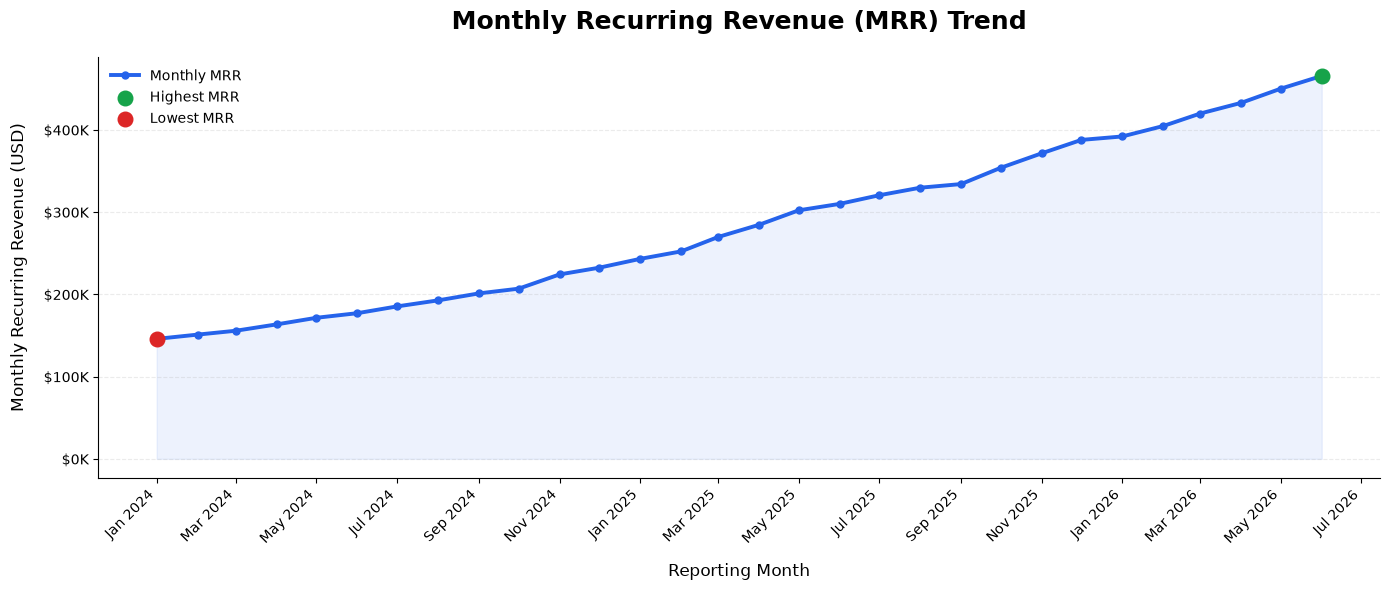

Monthly MRR Trend Chart created successfully.


In [15]:
# ==================================================
# Step 6.2.2 - Part F
# Professional Monthly MRR Trend Visualization
# ==================================================

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Create figure
fig, ax = plt.subplots(figsize=(14, 6))

# Plot Monthly MRR
ax.plot(
    monthly_mrr_trend["Month"],
    monthly_mrr_trend["Total_MRR_USD"],
    color="#2563EB",
    linewidth=2.8,
    marker="o",
    markersize=5,
    label="Monthly MRR"
)

# Add light blue area below line
ax.fill_between(
    monthly_mrr_trend["Month"],
    monthly_mrr_trend["Total_MRR_USD"],
    color="#2563EB",
    alpha=0.08
)

# Highlight highest MRR
ax.scatter(
    highest_month["Month"],
    highest_month["Total_MRR_USD"],
    color="#16A34A",
    s=110,
    zorder=5,
    label="Highest MRR"
)

# Highlight lowest MRR
ax.scatter(
    lowest_month["Month"],
    lowest_month["Total_MRR_USD"],
    color="#DC2626",
    s=110,
    zorder=5,
    label="Lowest MRR"
)

# Format Y-axis values
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"${x/1000:,.0f}K")
)

# Format X-axis dates
ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

# Chart title and labels
ax.set_title(
    "Monthly Recurring Revenue (MRR) Trend",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Reporting Month",
    fontsize=12,
    labelpad=12
)

ax.set_ylabel(
    "Monthly Recurring Revenue (USD)",
    fontsize=12,
    labelpad=12
)

# Chart styling
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    loc="best",
    frameon=False,
    fontsize=10
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Display chart
plt.show()

print("Monthly MRR Trend Chart created successfully.")

In [16]:
# ==================================================
# Step 6.2.2 - Part G
# Save Monthly MRR Trend Chart as PNG
# ==================================================

from pathlib import Path

# Define project root
project_root = Path.cwd().parent

# Define output folder
output_folder = project_root / "reports" / "figures"

# Create folder if it does not exist
output_folder.mkdir(
    parents=True,
    exist_ok=True
)

# Define PNG file path
output_path = (
    output_folder / "monthly_mrr_revenue_trend.png"
)

# Save chart in high resolution
fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

# Verify saved file
print("========== CHART SAVE VERIFICATION ==========")

print("Chart saved at:", output_path)
print("File exists:", output_path.exists())

if output_path.exists():
    print(
        "File size:",
        round(output_path.stat().st_size / 1024, 2),
        "KB"
    )

print("=============================================")

========== CHART SAVE VERIFICATION ==========
Chart saved at: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics\reports\figures\monthly_mrr_revenue_trend.png
File exists: True
File size: 232.61 KB


In [17]:
# ==================================================
# Step 6.2.3 - Part A
# Prepare and Validate Monthly MRR Growth Data
# ==================================================

# Select existing validated KPI columns
growth_columns = [
    "Month",
    "Total_MRR_USD",
    "Previous_Month_MRR",
    "MRR_Change_USD",
    "MRR_Growth_Pct"
]

monthly_growth = monthly_kpis[growth_columns].copy()

# Convert reporting month into datetime
monthly_growth["Month"] = pd.to_datetime(
    monthly_growth["Month"]
)

# Sort chronologically
monthly_growth = (
    monthly_growth
    .sort_values("Month")
    .reset_index(drop=True)
)

# Calculate previous month's MRR independently
monthly_growth["Calculated_Previous_MRR"] = (
    monthly_growth["Total_MRR_USD"].shift(1)
)

# Calculate MoM MRR change
monthly_growth["Calculated_MRR_Change"] = (
    monthly_growth["Total_MRR_USD"]
    - monthly_growth["Calculated_Previous_MRR"]
)

# Calculate MoM growth percentage
monthly_growth["Calculated_Growth_Pct"] = (
    monthly_growth["Calculated_MRR_Change"]
    / monthly_growth["Calculated_Previous_MRR"].replace(0, np.nan)
    * 100
)

# Validate growth percentage against existing KPI
growth_difference = (
    monthly_growth["Calculated_Growth_Pct"]
    - monthly_growth["MRR_Growth_Pct"]
).abs()

# Check both numeric differences and missing-value positions
missing_values_match = (
    monthly_growth["Calculated_Growth_Pct"].isna()
    == monthly_growth["MRR_Growth_Pct"].isna()
).all()

numeric_values_match = (
    growth_difference.dropna() <= 0.02
).all()

print("========== MoM GROWTH VALIDATION ==========")

print("Total reporting months:", len(monthly_growth))
print("Missing-value positions match:", missing_values_match)
print("Growth percentages match:", numeric_values_match)

if missing_values_match and numeric_values_match:
    print("MoM Growth Validation: PASS")
else:
    print("MoM Growth Validation: FAIL")

print("==========================================")

display(
    monthly_growth[
        [
            "Month",
            "Total_MRR_USD",
            "Previous_Month_MRR",
            "MRR_Growth_Pct",
            "Calculated_Growth_Pct"
        ]
    ].head(10)
)

========== MoM GROWTH VALIDATION ==========
Total reporting months: 30
Missing-value positions match: True
Growth percentages match: True
MoM Growth Validation: PASS


,Month,Total_MRR_USD,Previous_Month_MRR,MRR_Growth_Pct,Calculated_Growth_Pct
0,2024-01-01,145853.24,NaN,NaN,NaN
1,2024-02-01,151051.80,145853.24,3.56,3.564240
2,2024-03-01,155769.21,151051.80,3.12,3.123041
3,2024-04-01,163530.40,155769.21,4.98,4.982493
4,2024-05-01,171524.29,163530.40,4.89,4.888320
5,2024-06-01,177113.30,171524.29,3.26,3.258436
6,2024-07-01,185335.76,177113.30,4.64,4.642486
7,2024-08-01,192664.71,185335.76,3.95,3.954418
8,2024-09-01,201173.32,192664.71,4.42,4.416278
9,2024-10-01,206885.58,201173.32,2.84,2.839472


In [18]:

# ==================================================
# Step 6.2.3 - Part B
# Monthly MRR Growth Business Insights
# ==================================================

# Exclude months where growth is unavailable
valid_growth = monthly_growth.dropna(
    subset=["MRR_Growth_Pct"]
).copy()

# Count positive, negative and zero growth months
positive_growth_months = (
    valid_growth["MRR_Growth_Pct"] > 0
).sum()

negative_growth_months = (
    valid_growth["MRR_Growth_Pct"] < 0
).sum()

zero_growth_months = (
    valid_growth["MRR_Growth_Pct"] == 0
).sum()

# Identify highest and lowest growth months
if valid_growth.empty:
    print("No valid monthly growth records available.")

else:
    highest_growth = valid_growth.loc[
        valid_growth["MRR_Growth_Pct"].idxmax()
    ]

    lowest_growth = valid_growth.loc[
        valid_growth["MRR_Growth_Pct"].idxmin()
    ]

    # Calculate average and median MoM growth
    average_growth = valid_growth["MRR_Growth_Pct"].mean()
    median_growth = valid_growth["MRR_Growth_Pct"].median()

    print("========== MONTHLY MRR GROWTH INSIGHTS ==========")

    print("Total growth months:", len(valid_growth))

    print("Positive growth months:", positive_growth_months)
    print("Negative growth months:", negative_growth_months)
    print("Zero growth months:", zero_growth_months)

    print(
        "\nHighest Growth Month:",
        highest_growth["Month"].strftime("%b %Y")
    )
    print(
        f"Highest Growth Rate: "
        f"{highest_growth['MRR_Growth_Pct']:.2f}%"
    )

    print(
        "\nLowest Growth Month:",
        lowest_growth["Month"].strftime("%b %Y")
    )
    print(
        f"Lowest Growth Rate: "
        f"{lowest_growth['MRR_Growth_Pct']:.2f}%"
    )

    print(f"\nAverage MoM Growth: {average_growth:.2f}%")
    print(f"Median MoM Growth: {median_growth:.2f}%")

    # Verify growth month counts
    total_classified = (
        positive_growth_months
        + negative_growth_months
        + zero_growth_months
    )

    print("\nClassified Growth Months:", total_classified)

    assert total_classified == len(valid_growth), (
        "Growth month classification mismatch."
    )

    print("Growth Classification Validation: PASS")
    print("================================================")


========== MONTHLY MRR GROWTH INSIGHTS ==========
Total growth months: 29
Positive growth months: 29
Negative growth months: 0
Zero growth months: 0

Highest Growth Month: Nov 2024
Highest Growth Rate: 8.38%

Lowest Growth Month: Jan 2026
Lowest Growth Rate: 1.08%

Average MoM Growth: 4.09%
Median MoM Growth: 3.75%

Classified Growth Months: 29
Growth Classification Validation: PASS


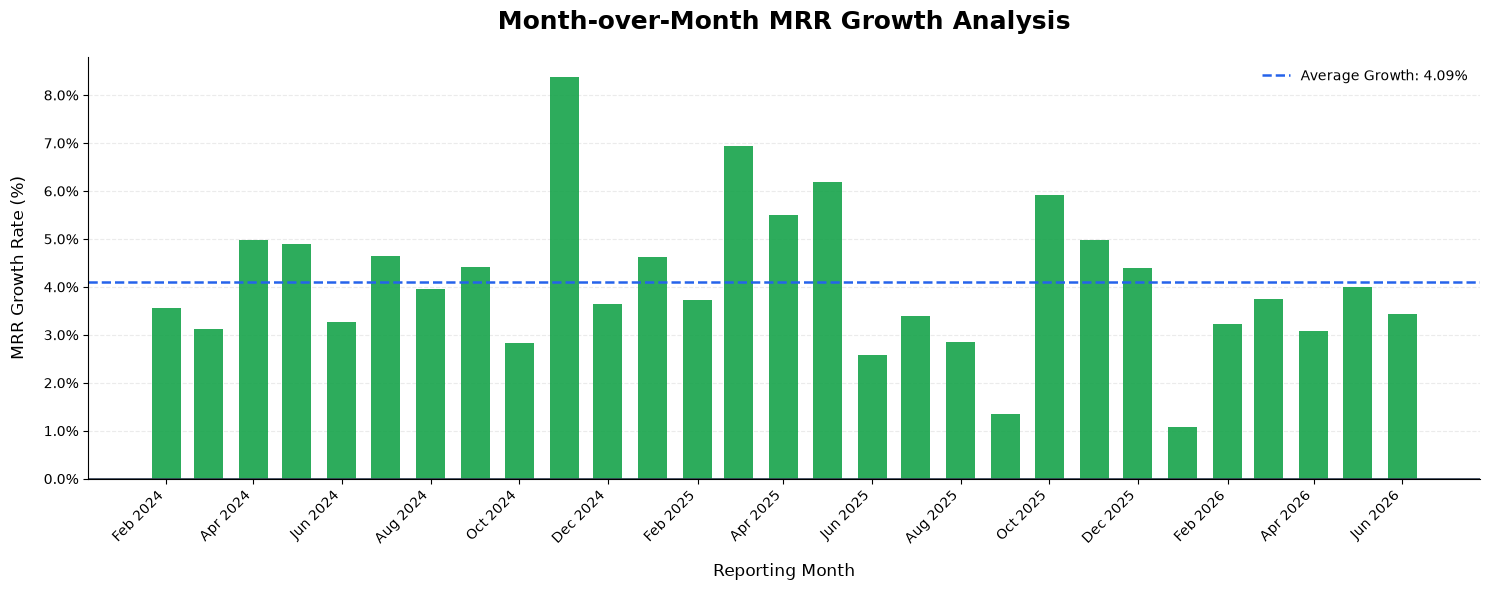

Monthly MRR Growth Chart created successfully.


In [19]:

# ==================================================
# Step 6.2.3 - Part C
# Professional Monthly MRR Growth Visualization
# ==================================================

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Prepare chart data
growth_chart_data = monthly_growth.dropna(
    subset=["MRR_Growth_Pct"]
).copy()

growth_chart_data = growth_chart_data.sort_values("Month")

# Assign colors based on growth direction
bar_colors = [
    "#16A34A" if value > 0
    else "#DC2626" if value < 0
    else "#94A3B8"
    for value in growth_chart_data["MRR_Growth_Pct"]
]

# Create chart
fig_growth, ax_growth = plt.subplots(figsize=(15, 6))

# Plot growth bars
ax_growth.bar(
    growth_chart_data["Month"],
    growth_chart_data["MRR_Growth_Pct"],
    width=20,
    color=bar_colors,
    alpha=0.9
)

# Add zero reference line
ax_growth.axhline(
    y=0,
    color="#334155",
    linewidth=1.2
)

# Add average growth reference line
ax_growth.axhline(
    y=average_growth,
    color="#2563EB",
    linestyle="--",
    linewidth=1.8,
    label=f"Average Growth: {average_growth:.2f}%"
)

# Format X-axis
ax_growth.xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)

ax_growth.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

# Format Y-axis
ax_growth.yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:.1f}%")
)

# Add chart title and labels
ax_growth.set_title(
    "Month-over-Month MRR Growth Analysis",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax_growth.set_xlabel(
    "Reporting Month",
    fontsize=12,
    labelpad=12
)

ax_growth.set_ylabel(
    "MRR Growth Rate (%)",
    fontsize=12,
    labelpad=12
)

# Chart styling
ax_growth.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax_growth.set_axisbelow(True)

ax_growth.spines["top"].set_visible(False)
ax_growth.spines["right"].set_visible(False)

ax_growth.legend(
    loc="best",
    frameon=False,
    fontsize=10
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Display chart
plt.show()

print("Monthly MRR Growth Chart created successfully.")


In [20]:

# ==================================================
# Step 6.2.3 - Part D
# Save Monthly MRR Growth Chart as PNG
# ==================================================

from pathlib import Path

# Define project root
project_root = Path.cwd().parent

# Define output folder
output_folder = project_root / "reports" / "figures"

# Create output folder if needed
output_folder.mkdir(
    parents=True,
    exist_ok=True
)

# Define chart output path
growth_chart_path = (
    output_folder / "monthly_mrr_growth_analysis.png"
)

# Save chart in high resolution
fig_growth.savefig(
    growth_chart_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

# Verify saved file
print("========== MRR GROWTH CHART VERIFICATION ==========")

print("Chart saved at:", growth_chart_path)
print("File exists:", growth_chart_path.exists())

if growth_chart_path.exists():
    print(
        "File size:",
        round(growth_chart_path.stat().st_size / 1024, 2),
        "KB"
    )

print("===================================================")


========== MRR GROWTH CHART VERIFICATION ==========
Chart saved at: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics\reports\figures\monthly_mrr_growth_analysis.png
File exists: True
File size: 197.18 KB


In [21]:

# ==================================================
# Step 6.2.4 - Part A
# Prepare and Validate MRR Movement Data
# ==================================================

# Select required MRR movement columns
movement_columns = [
    "Month",
    "Total_MRR_USD",
    "Previous_Month_MRR",
    "New_MRR",
    "Expansion_MRR",
    "Contraction_MRR",
    "Churn_MRR",
    "Reactivation_MRR",
    "Net_MRR_Change",
    "MRR_Change_USD"
]

# Create independent analysis dataframe
mrr_movements = monthly_kpis[movement_columns].copy()

# Convert reporting month to datetime
mrr_movements["Month"] = pd.to_datetime(
    mrr_movements["Month"],
    errors="coerce"
)

# Convert numeric columns
numeric_columns = [
    col for col in movement_columns
    if col != "Month"
]

mrr_movements[numeric_columns] = (
    mrr_movements[numeric_columns]
    .apply(pd.to_numeric, errors="coerce")
)

# Sort by reporting month
mrr_movements = (
    mrr_movements
    .sort_values("Month")
    .reset_index(drop=True)
)

# Validate reporting months and movement components
assert mrr_movements["Month"].notna().all(), \
    "Invalid reporting month found."

assert not mrr_movements["Month"].duplicated().any(), \
    "Duplicate reporting months found."

component_columns = [
    "New_MRR",
    "Expansion_MRR",
    "Contraction_MRR",
    "Churn_MRR",
    "Reactivation_MRR"
]

assert mrr_movements[component_columns].notna().all().all(), \
    "Missing MRR movement component values found."

assert (mrr_movements[component_columns] >= 0).all().all(), \
    "Negative MRR movement component values found."

# Independently calculate net MRR change
mrr_movements["Calculated_Net_MRR_Change"] = (
    mrr_movements["New_MRR"]
    + mrr_movements["Expansion_MRR"]
    + mrr_movements["Reactivation_MRR"]
    - mrr_movements["Contraction_MRR"]
    - mrr_movements["Churn_MRR"]
)

# Compare calculated and existing net MRR change
movement_difference = (
    mrr_movements["Calculated_Net_MRR_Change"]
    - mrr_movements["Net_MRR_Change"]
).abs()

# Validate existing KPI values
assert mrr_movements["Net_MRR_Change"].notna().all(), \
    "Missing Net_MRR_Change values found."

movement_validation_passed = (
    movement_difference <= 0.05
).all()

print("========== MRR MOVEMENT VALIDATION ==========")

print("Total reporting months:", len(mrr_movements))

print(
    "Movement formula validation:",
    "PASS" if movement_validation_passed else "FAIL"
)

print(
    "Maximum formula difference (USD):",
    round(movement_difference.max(), 4)
)

print("=============================================")

display(
    mrr_movements[
        [
            "Month",
            "New_MRR",
            "Expansion_MRR",
            "Contraction_MRR",
            "Churn_MRR",
            "Reactivation_MRR",
            "Net_MRR_Change",
            "Calculated_Net_MRR_Change"
        ]
    ].head(10)
)


========== MRR MOVEMENT VALIDATION ==========
Total reporting months: 30
Movement formula validation: PASS
Maximum formula difference (USD): 0.0


,Month,New_MRR,Expansion_MRR,Contraction_MRR,Churn_MRR,Reactivation_MRR,Net_MRR_Change,Calculated_Net_MRR_Change
0,2024-01-01,145853.24,0.00,-0.00,-0.00,0.00,145853.24,145853.24
1,2024-02-01,6830.65,1276.20,615.40,2292.89,0.00,5198.56,5198.56
2,2024-03-01,2047.34,5748.80,279.40,2799.33,0.00,4717.41,4717.41
3,2024-04-01,5965.74,4819.65,375.20,2649.00,0.00,7761.19,7761.19
4,2024-05-01,3828.17,6698.50,204.00,2328.78,0.00,7993.89,7993.89
5,2024-06-01,3817.41,2940.90,476.45,1152.68,459.83,5589.01,5589.01
6,2024-07-01,3074.51,6576.40,202.80,1225.65,0.00,8222.46,8222.46
7,2024-08-01,3229.45,5302.75,183.10,1069.15,49.00,7328.95,7328.95
8,2024-09-01,7906.86,3347.10,369.80,2672.55,297.00,8508.61,8508.61
9,2024-10-01,7409.21,3350.60,85.20,4962.35,0.00,5712.26,5712.26


In [22]:

# ==================================================
# Step 6.2.4 - Part B
# MRR Movement Business Insights Analysis
# ==================================================

# Calculate total MRR movements across reporting months
total_new_mrr = mrr_movements["New_MRR"].sum()
total_expansion_mrr = mrr_movements["Expansion_MRR"].sum()
total_reactivation_mrr = mrr_movements["Reactivation_MRR"].sum()

total_contraction_mrr = mrr_movements["Contraction_MRR"].sum()
total_churn_mrr = mrr_movements["Churn_MRR"].sum()

# Calculate positive and negative MRR movements
total_positive_movements = (
    total_new_mrr
    + total_expansion_mrr
    + total_reactivation_mrr
)

total_negative_movements = (
    total_contraction_mrr
    + total_churn_mrr
)

# Calculate net MRR movement
total_net_mrr_movement = (
    total_positive_movements
    - total_negative_movements
)

# Identify months with highest new MRR and churn MRR
highest_new_mrr_month = mrr_movements.loc[
    mrr_movements["New_MRR"].idxmax()
]

highest_churn_mrr_month = mrr_movements.loc[
    mrr_movements["Churn_MRR"].idxmax()
]

# Calculate movement contribution percentages
new_mrr_share = (
    total_new_mrr / total_positive_movements * 100
    if total_positive_movements != 0 else np.nan
)

expansion_mrr_share = (
    total_expansion_mrr / total_positive_movements * 100
    if total_positive_movements != 0 else np.nan
)

reactivation_mrr_share = (
    total_reactivation_mrr / total_positive_movements * 100
    if total_positive_movements != 0 else np.nan
)

# Validate total net movement
reported_net_mrr_movement = (
    mrr_movements["Net_MRR_Change"].sum()
)

net_movement_difference = abs(
    total_net_mrr_movement - reported_net_mrr_movement
)

assert net_movement_difference <= 0.05 * len(mrr_movements), (
    "Net MRR movement totals do not reconcile."
)

# Display business insights
print("========== MRR MOVEMENT BUSINESS INSIGHTS ==========")

print(f"Total New MRR: ${total_new_mrr:,.2f}")
print(f"Total Expansion MRR: ${total_expansion_mrr:,.2f}")
print(f"Total Reactivation MRR: ${total_reactivation_mrr:,.2f}")

print(f"\nTotal Contraction MRR: ${total_contraction_mrr:,.2f}")
print(f"Total Churn MRR: ${total_churn_mrr:,.2f}")

print(
    f"\nTotal Positive MRR Movements: "
    f"${total_positive_movements:,.2f}"
)

print(
    f"Total Negative MRR Movements: "
    f"${total_negative_movements:,.2f}"
)

print(
    f"Total Net MRR Movement: "
    f"${total_net_mrr_movement:,.2f}"
)

print(
    "\nHighest New MRR Month:",
    highest_new_mrr_month["Month"].strftime("%b %Y")
)

print(
    f"Highest Monthly New MRR: "
    f"${highest_new_mrr_month['New_MRR']:,.2f}"
)

print(
    "\nHighest Churn MRR Month:",
    highest_churn_mrr_month["Month"].strftime("%b %Y")
)

print(
    f"Highest Monthly Churn MRR: "
    f"${highest_churn_mrr_month['Churn_MRR']:,.2f}"
)

print("\n--- Positive MRR Movement Contributions ---")

print(f"New MRR Share: {new_mrr_share:.2f}%")
print(f"Expansion MRR Share: {expansion_mrr_share:.2f}%")
print(f"Reactivation MRR Share: {reactivation_mrr_share:.2f}%")

print("\nNet Movement Reconciliation: PASS")

print("====================================================")


========== MRR MOVEMENT BUSINESS INSIGHTS ==========
Total New MRR: $382,591.78
Total Expansion MRR: $189,736.59
Total Reactivation MRR: $5,496.37

Total Contraction MRR: $15,450.00
Total Churn MRR: $96,813.48

Total Positive MRR Movements: $577,824.74
Total Negative MRR Movements: $112,263.48
Total Net MRR Movement: $465,561.26

Highest New MRR Month: Jan 2024
Highest Monthly New MRR: $145,853.24

Highest Churn MRR Month: Feb 2025
Highest Monthly Churn MRR: $7,346.07

--- Positive MRR Movement Contributions ---
New MRR Share: 66.21%
Expansion MRR Share: 32.84%
Reactivation MRR Share: 0.95%

Net Movement Reconciliation: PASS


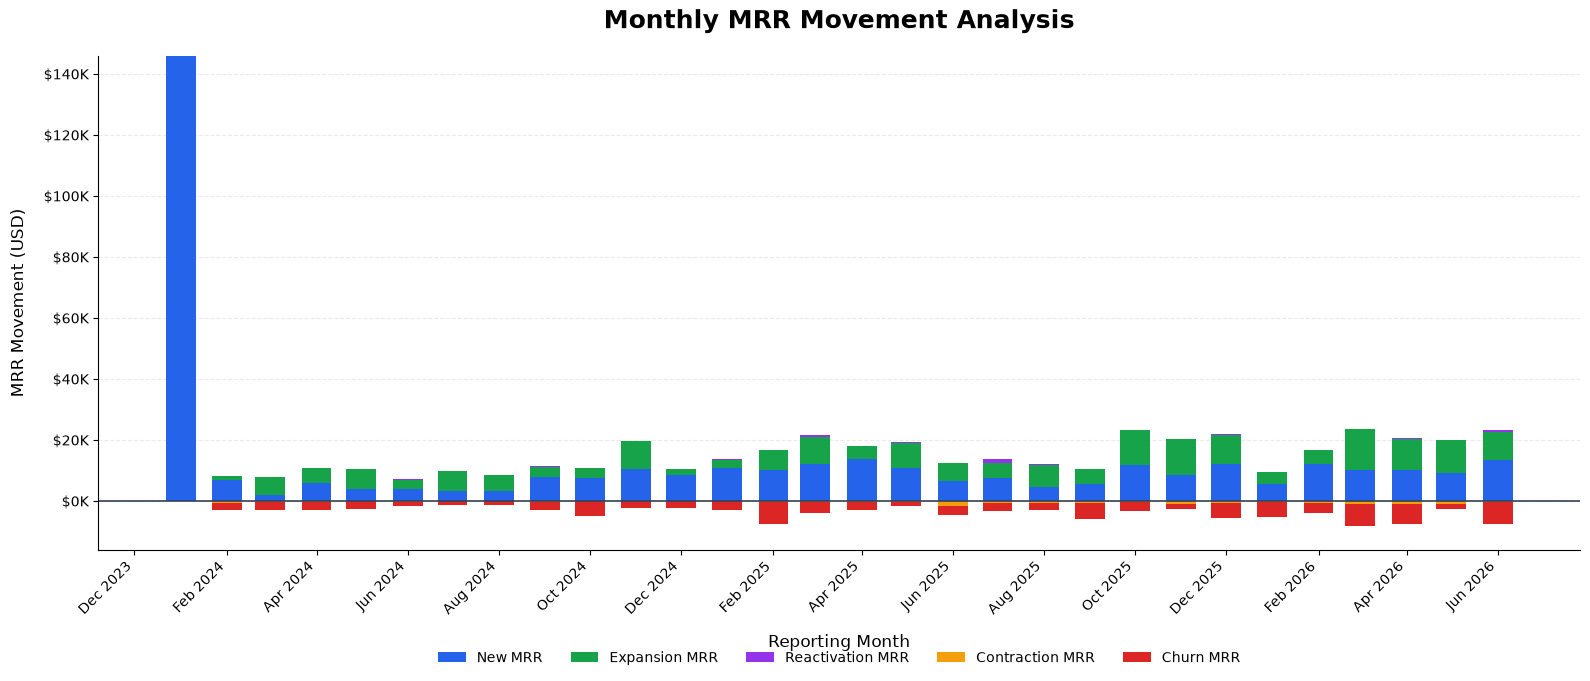

Monthly MRR Movement Chart created successfully.


In [23]:

# ==================================================
# Step 6.2.4 - Part C
# Professional Monthly MRR Movement Visualization
# ==================================================

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Prepare chart data
movement_chart_data = mrr_movements.sort_values(
    "Month"
).copy()

months = movement_chart_data["Month"]

# Positive MRR components
new_mrr = movement_chart_data["New_MRR"]
expansion_mrr = movement_chart_data["Expansion_MRR"]
reactivation_mrr = movement_chart_data["Reactivation_MRR"]

# Negative MRR components
contraction_mrr = -movement_chart_data["Contraction_MRR"]
churn_mrr = -movement_chart_data["Churn_MRR"]

# Create figure
fig_movement, ax_movement = plt.subplots(
    figsize=(16, 7)
)

# Positive stacked bars
ax_movement.bar(
    months,
    new_mrr,
    width=20,
    color="#2563EB",
    label="New MRR"
)

ax_movement.bar(
    months,
    expansion_mrr,
    bottom=new_mrr,
    width=20,
    color="#16A34A",
    label="Expansion MRR"
)

ax_movement.bar(
    months,
    reactivation_mrr,
    bottom=new_mrr + expansion_mrr,
    width=20,
    color="#9333EA",
    label="Reactivation MRR"
)

# Negative stacked bars
ax_movement.bar(
    months,
    contraction_mrr,
    width=20,
    color="#F59E0B",
    label="Contraction MRR"
)

ax_movement.bar(
    months,
    churn_mrr,
    bottom=contraction_mrr,
    width=20,
    color="#DC2626",
    label="Churn MRR"
)

# Zero reference line
ax_movement.axhline(
    y=0,
    color="#334155",
    linewidth=1.2
)

# Format X-axis
ax_movement.xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)

ax_movement.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

# Format Y-axis as USD thousands
ax_movement.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"${x / 1000:,.0f}K"
    )
)

# Chart title and labels
ax_movement.set_title(
    "Monthly MRR Movement Analysis",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax_movement.set_xlabel(
    "Reporting Month",
    fontsize=12,
    labelpad=12
)

ax_movement.set_ylabel(
    "MRR Movement (USD)",
    fontsize=12,
    labelpad=12
)

# Styling
ax_movement.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax_movement.set_axisbelow(True)

ax_movement.spines["top"].set_visible(False)
ax_movement.spines["right"].set_visible(False)

# Legend
ax_movement.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=5,
    frameon=False,
    fontsize=10
)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

# Display chart
plt.show()

print("Monthly MRR Movement Chart created successfully.")


In [24]:

# ==================================================
# Step 6.2.4 - Part D
# Save Monthly MRR Movement Chart as PNG
# ==================================================

from pathlib import Path

# Define project root
project_root = Path.cwd().parent

# Define output folder
output_folder = project_root / "reports" / "figures"

# Create folder if it does not exist
output_folder.mkdir(
    parents=True,
    exist_ok=True
)

# Define output file path
movement_chart_path = (
    output_folder / "monthly_mrr_movement_analysis.png"
)

# Save chart in high resolution
fig_movement.savefig(
    movement_chart_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

# Verify saved file
print("========== MRR MOVEMENT CHART VERIFICATION ==========")

print("Chart saved at:", movement_chart_path)
print("File exists:", movement_chart_path.exists())

if movement_chart_path.exists():
    file_size_kb = (
        movement_chart_path.stat().st_size / 1024
    )

    print(f"File size: {file_size_kb:.2f} KB")

    if file_size_kb > 10:
        print("File size check: PASS")
    else:
        print("File size check: REVIEW REQUIRED")

print("=====================================================")


========== MRR MOVEMENT CHART VERIFICATION ==========
Chart saved at: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics\reports\figures\monthly_mrr_movement_analysis.png
File exists: True
File size: 204.53 KB
File size check: PASS


In [25]:

# ==================================================
# Step 6.2.5 - Part A
# Prepare and Validate MRR Revenue Bridge
# ==================================================

import numpy as np
import pandas as pd

# Select required revenue bridge columns
bridge_columns = [
    "Month",
    "Opening_MRR_USD",
    "Total_MRR_USD",
    "New_MRR",
    "Expansion_MRR",
    "Reactivation_MRR",
    "Contraction_MRR",
    "Churn_MRR",
    "Net_MRR_Change"
]

# Prepare revenue bridge dataframe
revenue_bridge = monthly_kpis[bridge_columns].copy()

# Convert Month into datetime
revenue_bridge["Month"] = pd.to_datetime(
    revenue_bridge["Month"],
    errors="coerce"
)

# Convert numeric columns
numeric_columns = [
    col for col in bridge_columns
    if col != "Month"
]

revenue_bridge[numeric_columns] = (
    revenue_bridge[numeric_columns]
    .apply(pd.to_numeric, errors="coerce")
)

# Sort by month
revenue_bridge = (
    revenue_bridge
    .sort_values("Month")
    .reset_index(drop=True)
)

# Validate dates and numeric values
assert revenue_bridge["Month"].notna().all(), \
    "Invalid reporting months found."

assert not revenue_bridge["Month"].duplicated().any(), \
    "Duplicate reporting months found."

assert revenue_bridge[numeric_columns].notna().all().all(), \
    "Missing numeric values found."

# Independently calculate closing MRR
revenue_bridge["Calculated_Closing_MRR"] = (
    revenue_bridge["Opening_MRR_USD"]
    + revenue_bridge["New_MRR"]
    + revenue_bridge["Expansion_MRR"]
    + revenue_bridge["Reactivation_MRR"]
    - revenue_bridge["Contraction_MRR"]
    - revenue_bridge["Churn_MRR"]
)

# Calculate reconciliation difference
revenue_bridge["Bridge_Difference"] = (
    revenue_bridge["Calculated_Closing_MRR"]
    - revenue_bridge["Total_MRR_USD"]
)

# Validate reconciliation
tolerance = 0.05

revenue_bridge["Reconciliation_Status"] = np.where(
    revenue_bridge["Bridge_Difference"].abs() <= tolerance,
    "PASS",
    "FAIL"
)

# Display results
print("========== MRR REVENUE BRIDGE VALIDATION ==========")

print("Total reporting months:", len(revenue_bridge))

print(
    "Months passed:",
    (revenue_bridge["Reconciliation_Status"] == "PASS").sum()
)

print(
    "Months failed:",
    (revenue_bridge["Reconciliation_Status"] == "FAIL").sum()
)

print(
    "Maximum reconciliation difference:",
    round(revenue_bridge["Bridge_Difference"].abs().max(), 4)
)

if (revenue_bridge["Reconciliation_Status"] == "PASS").all():
    print("Revenue Bridge Validation: PASS")
else:
    print("Revenue Bridge Validation: FAIL")

print("===================================================")

display(
    revenue_bridge[
        [
            "Month",
            "Opening_MRR_USD",
            "Net_MRR_Change",
            "Calculated_Closing_MRR",
            "Total_MRR_USD",
            "Bridge_Difference",
            "Reconciliation_Status"
        ]
    ].head(10)
)


========== MRR REVENUE BRIDGE VALIDATION ==========
Total reporting months: 30
Months passed: 30
Months failed: 0
Maximum reconciliation difference: 0.0
Revenue Bridge Validation: PASS


,Month,Opening_MRR_USD,Net_MRR_Change,Calculated_Closing_MRR,Total_MRR_USD,Bridge_Difference,Reconciliation_Status
0,2024-01-01,0.00,145853.24,145853.24,145853.24,0.000000e+00,PASS
1,2024-02-01,145853.24,5198.56,151051.80,151051.80,0.000000e+00,PASS
2,2024-03-01,151051.80,4717.41,155769.21,155769.21,0.000000e+00,PASS
3,2024-04-01,155769.21,7761.19,163530.40,163530.40,-2.910383e-11,PASS
4,2024-05-01,163530.40,7993.89,171524.29,171524.29,0.000000e+00,PASS
5,2024-06-01,171524.29,5589.01,177113.30,177113.30,0.000000e+00,PASS
6,2024-07-01,177113.30,8222.46,185335.76,185335.76,0.000000e+00,PASS
7,2024-08-01,185335.76,7328.95,192664.71,192664.71,2.910383e-11,PASS
8,2024-09-01,192664.71,8508.61,201173.32,201173.32,0.000000e+00,PASS
9,2024-10-01,201173.32,5712.26,206885.58,206885.58,0.000000e+00,PASS


In [26]:

# ==================================================
# Step 6.2.5 - Part B
# MRR Revenue Bridge Business Insights Analysis
# ==================================================

# Validate that all monthly bridges reconciled
assert (
    revenue_bridge["Reconciliation_Status"] == "PASS"
).all(), "Some revenue bridge records did not reconcile."

# Identify first and last reporting months
first_bridge_month = revenue_bridge.iloc[0]
last_bridge_month = revenue_bridge.iloc[-1]

# Extract opening and closing MRR
initial_opening_mrr = first_bridge_month["Opening_MRR_USD"]
final_closing_mrr = last_bridge_month["Total_MRR_USD"]

# Calculate overall MRR change
overall_mrr_change = (
    final_closing_mrr - initial_opening_mrr
)

overall_mrr_change_pct = (
    overall_mrr_change / initial_opening_mrr * 100
    if initial_opening_mrr != 0
    else np.nan
)

# Identify highest and lowest net MRR change months
highest_net_change_month = revenue_bridge.loc[
    revenue_bridge["Net_MRR_Change"].idxmax()
]

lowest_net_change_month = revenue_bridge.loc[
    revenue_bridge["Net_MRR_Change"].idxmin()
]

# Calculate cumulative net MRR movement
cumulative_net_mrr_change = (
    revenue_bridge["Net_MRR_Change"].sum()
)

# Validate continuity between reporting months
revenue_bridge["Previous_Closing_MRR"] = (
    revenue_bridge["Total_MRR_USD"].shift(1)
)

continuity_difference = (
    revenue_bridge["Opening_MRR_USD"]
    - revenue_bridge["Previous_Closing_MRR"]
).abs()

continuity_passed = (
    continuity_difference.iloc[1:] <= 0.05
).all()

# Reconcile cumulative movements to overall MRR change
overall_difference = abs(
    cumulative_net_mrr_change - overall_mrr_change
)

overall_validation_passed = (
    continuity_passed
    and overall_difference <= 0.05 * len(revenue_bridge)
)

# Display business insights
print("========== MRR REVENUE BRIDGE BUSINESS INSIGHTS ==========")

print(
    "First Reporting Month:",
    first_bridge_month["Month"].strftime("%b %Y")
)

print(
    "Last Reporting Month:",
    last_bridge_month["Month"].strftime("%b %Y")
)

print(f"\nInitial Opening MRR: ${initial_opening_mrr:,.2f}")
print(f"Final Closing MRR: ${final_closing_mrr:,.2f}")

print(f"\nOverall MRR Change: ${overall_mrr_change:,.2f}")
print(f"Overall MRR Change (%): {overall_mrr_change_pct:.2f}%")

print(
    "\nHighest Net MRR Change Month:",
    highest_net_change_month["Month"].strftime("%b %Y")
)

print(
    f"Highest Monthly Net MRR Change: "
    f"${highest_net_change_month['Net_MRR_Change']:,.2f}"
)

print(
    "\nLowest Net MRR Change Month:",
    lowest_net_change_month["Month"].strftime("%b %Y")
)

print(
    f"Lowest Monthly Net MRR Change: "
    f"${lowest_net_change_month['Net_MRR_Change']:,.2f}"
)

print(
    f"\nCumulative Net MRR Movement: "
    f"${cumulative_net_mrr_change:,.2f}"
)

print(
    "\nMonth-to-Month Continuity:",
    "PASS" if continuity_passed else "FAIL"
)

print(
    "Overall Bridge Reconciliation:",
    "PASS" if overall_validation_passed else "FAIL"
)

print("==========================================================")

# Display first five months for review
display(
    revenue_bridge[
        [
            "Month",
            "Opening_MRR_USD",
            "Net_MRR_Change",
            "Total_MRR_USD",
            "Previous_Closing_MRR"
        ]
    ].head()
)


========== MRR REVENUE BRIDGE BUSINESS INSIGHTS ==========
First Reporting Month: Jan 2024
Last Reporting Month: Jun 2026

Initial Opening MRR: $0.00
Final Closing MRR: $465,561.26

Overall MRR Change: $465,561.26
Overall MRR Change (%): nan%

Highest Net MRR Change Month: Jan 2024
Highest Monthly Net MRR Change: $145,853.24

Lowest Net MRR Change Month: Jan 2026
Lowest Monthly Net MRR Change: $4,206.89

Cumulative Net MRR Movement: $465,561.26

Month-to-Month Continuity: PASS
Overall Bridge Reconciliation: PASS


,Month,Opening_MRR_USD,Net_MRR_Change,Total_MRR_USD,Previous_Closing_MRR
0,2024-01-01,0.00,145853.24,145853.24,NaN
1,2024-02-01,145853.24,5198.56,151051.80,145853.24
2,2024-03-01,151051.80,4717.41,155769.21,151051.80
3,2024-04-01,155769.21,7761.19,163530.40,155769.21
4,2024-05-01,163530.40,7993.89,171524.29,163530.40


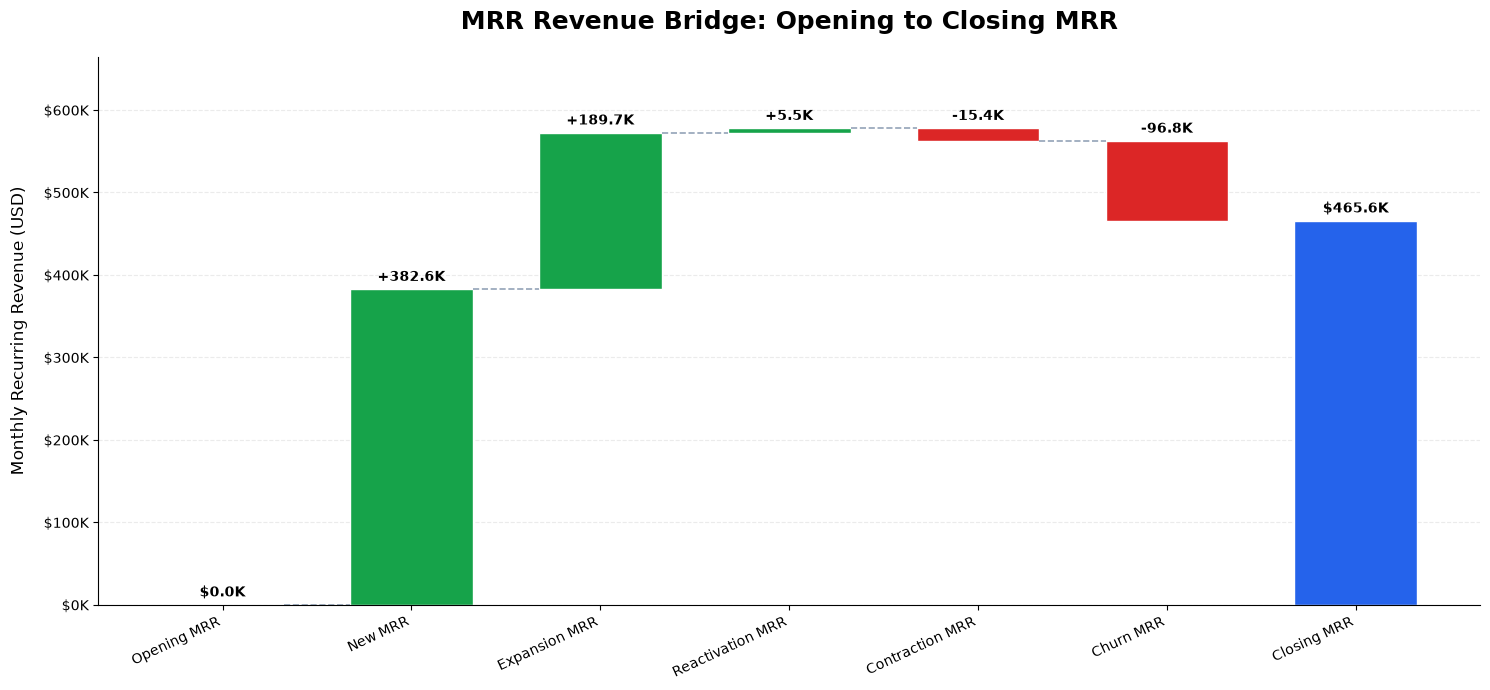

MRR Revenue Bridge Waterfall Chart created successfully.
Waterfall Reconciliation: PASS


In [27]:

# ==================================================
# Step 6.2.5 - Part C
# Professional MRR Revenue Bridge Waterfall Chart
# ==================================================

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Use first opening and last closing MRR
opening_mrr = float(initial_opening_mrr)
closing_mrr = float(final_closing_mrr)

# Aggregate MRR movements across the reporting period
bridge_labels = [
    "Opening MRR",
    "New MRR",
    "Expansion MRR",
    "Reactivation MRR",
    "Contraction MRR",
    "Churn MRR",
    "Closing MRR"
]

bridge_changes = [
    total_new_mrr,
    total_expansion_mrr,
    total_reactivation_mrr,
    -total_contraction_mrr,
    -total_churn_mrr
]

# Calculate waterfall bar positions
bar_bottoms = [0]
bar_heights = [opening_mrr]
bar_colors = ["#2563EB"]

running_total = opening_mrr
running_totals = [opening_mrr]

for change in bridge_changes:

    next_total = running_total + change

    bar_bottoms.append(min(running_total, next_total))
    bar_heights.append(abs(change))

    bar_colors.append(
        "#16A34A" if change >= 0 else "#DC2626"
    )

    running_total = next_total
    running_totals.append(running_total)

# Add final closing MRR bar
bar_bottoms.append(0)
bar_heights.append(closing_mrr)
bar_colors.append("#2563EB")

# Verify waterfall reconciliation
assert abs(running_total - closing_mrr) <= (
    0.05 * len(revenue_bridge)
), "Waterfall closing MRR does not reconcile."

# Create chart
fig_bridge, ax_bridge = plt.subplots(
    figsize=(15, 7)
)

x_positions = list(range(len(bridge_labels)))

ax_bridge.bar(
    x_positions,
    bar_heights,
    bottom=bar_bottoms,
    color=bar_colors,
    width=0.65,
    edgecolor="white",
    linewidth=1
)

# Add waterfall connector lines
for i in range(len(running_totals) - 1):
    ax_bridge.plot(
        [i + 0.325, i + 0.675],
        [running_totals[i], running_totals[i]],
        color="#94A3B8",
        linestyle="--",
        linewidth=1.2
    )

# Format Y-axis
ax_bridge.yaxis.set_major_formatter(
    FuncFormatter(
        lambda value, pos: f"${value / 1000:,.0f}K"
    )
)

# Titles and labels
ax_bridge.set_title(
    "MRR Revenue Bridge: Opening to Closing MRR",
    fontsize=18,
    fontweight="bold",
    pad=20
)

ax_bridge.set_ylabel(
    "Monthly Recurring Revenue (USD)",
    fontsize=12,
    labelpad=12
)

ax_bridge.set_xticks(x_positions)
ax_bridge.set_xticklabels(
    bridge_labels,
    rotation=25,
    ha="right"
)

# Add value labels
for i, (bottom, height) in enumerate(
    zip(bar_bottoms, bar_heights)
):

    if i == 0:
        label_value = opening_mrr
        label = f"${label_value / 1000:,.1f}K"

    elif i == len(bridge_labels) - 1:
        label_value = closing_mrr
        label = f"${label_value / 1000:,.1f}K"

    else:
        label_value = bridge_changes[i - 1]
        label = f"{label_value / 1000:+,.1f}K"

    ax_bridge.annotate(
        label,
        xy=(i, bottom + height),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

# Chart styling
ax_bridge.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax_bridge.set_axisbelow(True)

ax_bridge.spines["top"].set_visible(False)
ax_bridge.spines["right"].set_visible(False)

ax_bridge.margins(y=0.15)

plt.tight_layout()
plt.show()

print("MRR Revenue Bridge Waterfall Chart created successfully.")
print("Waterfall Reconciliation: PASS")


In [28]:

# ==================================================
# Step 6.2.5 - Part D
# Save MRR Revenue Bridge Waterfall Chart as PNG
# ==================================================

from pathlib import Path

# Define project root
project_root = Path.cwd().parent

# Define output folder
output_folder = project_root / "reports" / "figures"

# Create output folder if it does not exist
output_folder.mkdir(
    parents=True,
    exist_ok=True
)

# Define PNG file path
bridge_chart_path = (
    output_folder / "mrr_revenue_bridge_waterfall.png"
)

# Save chart in high resolution
fig_bridge.savefig(
    bridge_chart_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

# Verify saved file
print("========== REVENUE BRIDGE CHART VERIFICATION ==========")

print("Chart saved at:", bridge_chart_path)
print("File exists:", bridge_chart_path.exists())

if bridge_chart_path.exists():

    file_size_kb = (
        bridge_chart_path.stat().st_size / 1024
    )

    print(f"File size: {file_size_kb:.2f} KB")

    if file_size_kb > 10:
        print("File size check: PASS")
    else:
        print("File size check: REVIEW REQUIRED")

print("=======================================================")


========== REVENUE BRIDGE CHART VERIFICATION ==========
Chart saved at: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics\reports\figures\mrr_revenue_bridge_waterfall.png
File exists: True
File size: 197.27 KB
File size check: PASS


In [29]:

# ==================================================
# Step 6.2.6 - Part A
# Consolidated Revenue Trend Business Findings
# ==================================================

# Validate the previously completed analyses
assert not monthly_mrr_trend.empty, "MRR trend data is empty."
assert not valid_growth.empty, "Growth analysis data is empty."
assert not mrr_movements.empty, "MRR movement data is empty."

assert (
    revenue_bridge["Reconciliation_Status"] == "PASS"
).all(), "Revenue bridge validation failed."

assert overall_validation_passed, (
    "Overall revenue bridge reconciliation failed."
)

# Prepare consolidated business findings
revenue_findings = {
    "First Reporting Month":
        first_month["Month"].strftime("%b %Y"),

    "Last Reporting Month":
        last_month["Month"].strftime("%b %Y"),

    "First Month Closing MRR (USD)":
        round(float(first_mrr), 2),

    "Last Month Closing MRR (USD)":
        round(float(last_mrr), 2),

    "First-to-Last Closing MRR Change (USD)":
        round(float(absolute_change), 2),

    "First-to-Last Closing MRR Change (%)":
        round(float(percentage_change), 2),

    "Highest MRR Month":
        highest_month["Month"].strftime("%b %Y"),

    "Highest Monthly MRR (USD)":
        round(float(highest_month["Total_MRR_USD"]), 2),

    "Lowest MRR Month":
        lowest_month["Month"].strftime("%b %Y"),

    "Lowest Monthly MRR (USD)":
        round(float(lowest_month["Total_MRR_USD"]), 2),

    "Average MoM Growth (%)":
        round(float(average_growth), 2),

    "Median MoM Growth (%)":
        round(float(median_growth), 2),

    "Positive Growth Months":
        int(positive_growth_months),

    "Negative Growth Months":
        int(negative_growth_months),

    "Zero Growth Months":
        int(zero_growth_months),

    "Highest Growth Month":
        highest_growth["Month"].strftime("%b %Y"),

    "Highest MoM Growth (%)":
        round(float(highest_growth["MRR_Growth_Pct"]), 2),

    "Lowest Growth Month":
        lowest_growth["Month"].strftime("%b %Y"),

    "Lowest MoM Growth (%)":
        round(float(lowest_growth["MRR_Growth_Pct"]), 2),

    "Total New MRR Movements (USD)":
        round(float(total_new_mrr), 2),

    "Total Expansion MRR Movements (USD)":
        round(float(total_expansion_mrr), 2),

    "Total Reactivation MRR Movements (USD)":
        round(float(total_reactivation_mrr), 2),

    "Total Contraction MRR Movements (USD)":
        round(float(total_contraction_mrr), 2),

    "Total Churn MRR Movements (USD)":
        round(float(total_churn_mrr), 2),

    "Initial Opening MRR (USD)":
        round(float(initial_opening_mrr), 2),

    "Final Closing MRR (USD)":
        round(float(final_closing_mrr), 2),

    "Overall Revenue Bridge Change (USD)":
        round(float(overall_mrr_change), 2),

    "Revenue Bridge Reconciliation":
        "PASS"
}

# Convert findings into a structured DataFrame
revenue_findings_df = pd.DataFrame(
    revenue_findings.items(),
    columns=["Business_Metric", "Value"]
)

print("========== REVENUE TREND BUSINESS FINDINGS ==========")

print("Total business metrics:", len(revenue_findings_df))
print("Revenue Bridge Reconciliation: PASS")

print("=====================================================")

display(revenue_findings_df)


========== REVENUE TREND BUSINESS FINDINGS ==========
Total business metrics: 28
Revenue Bridge Reconciliation: PASS


,Business_Metric,Value
0,First Reporting Month,Jan 2024
1,Last Reporting Month,Jun 2026
2,First Month Closing MRR (USD),145853.24
3,Last Month Closing MRR (USD),465561.26
4,First-to-Last Closing MRR Change (USD),319708.02
5,First-to-Last Closing MRR Change (%),219.2
6,Highest MRR Month,Jun 2026
7,Highest Monthly MRR (USD),465561.26
8,Lowest MRR Month,Jan 2024
9,Lowest Monthly MRR (USD),145853.24


In [30]:

# ==================================================
# Step 6.2.6 - Part A
# Consolidated Revenue Trend Business Findings
# ==================================================

# Validate the previously completed analyses
assert not monthly_mrr_trend.empty, "MRR trend data is empty."
assert not valid_growth.empty, "Growth analysis data is empty."
assert not mrr_movements.empty, "MRR movement data is empty."

assert (
    revenue_bridge["Reconciliation_Status"] == "PASS"
).all(), "Revenue bridge validation failed."

assert overall_validation_passed, (
    "Overall revenue bridge reconciliation failed."
)

# Prepare consolidated business findings
revenue_findings = {
    "First Reporting Month":
        first_month["Month"].strftime("%b %Y"),

    "Last Reporting Month":
        last_month["Month"].strftime("%b %Y"),

    "First Month Closing MRR (USD)":
        round(float(first_mrr), 2),

    "Last Month Closing MRR (USD)":
        round(float(last_mrr), 2),

    "First-to-Last Closing MRR Change (USD)":
        round(float(absolute_change), 2),

    "First-to-Last Closing MRR Change (%)":
        round(float(percentage_change), 2),

    "Highest MRR Month":
        highest_month["Month"].strftime("%b %Y"),

    "Highest Monthly MRR (USD)":
        round(float(highest_month["Total_MRR_USD"]), 2),

    "Lowest MRR Month":
        lowest_month["Month"].strftime("%b %Y"),

    "Lowest Monthly MRR (USD)":
        round(float(lowest_month["Total_MRR_USD"]), 2),

    "Average MoM Growth (%)":
        round(float(average_growth), 2),

    "Median MoM Growth (%)":
        round(float(median_growth), 2),

    "Positive Growth Months":
        int(positive_growth_months),

    "Negative Growth Months":
        int(negative_growth_months),

    "Zero Growth Months":
        int(zero_growth_months),

    "Highest Growth Month":
        highest_growth["Month"].strftime("%b %Y"),

    "Highest MoM Growth (%)":
        round(float(highest_growth["MRR_Growth_Pct"]), 2),

    "Lowest Growth Month":
        lowest_growth["Month"].strftime("%b %Y"),

    "Lowest MoM Growth (%)":
        round(float(lowest_growth["MRR_Growth_Pct"]), 2),

    "Total New MRR Movements (USD)":
        round(float(total_new_mrr), 2),

    "Total Expansion MRR Movements (USD)":
        round(float(total_expansion_mrr), 2),

    "Total Reactivation MRR Movements (USD)":
        round(float(total_reactivation_mrr), 2),

    "Total Contraction MRR Movements (USD)":
        round(float(total_contraction_mrr), 2),

    "Total Churn MRR Movements (USD)":
        round(float(total_churn_mrr), 2),

    "Initial Opening MRR (USD)":
        round(float(initial_opening_mrr), 2),

    "Final Closing MRR (USD)":
        round(float(final_closing_mrr), 2),

    "Overall Revenue Bridge Change (USD)":
        round(float(overall_mrr_change), 2),

    "Revenue Bridge Reconciliation":
        "PASS"
}

# Convert findings into a structured DataFrame
revenue_findings_df = pd.DataFrame(
    revenue_findings.items(),
    columns=["Business_Metric", "Value"]
)

print("========== REVENUE TREND BUSINESS FINDINGS ==========")

print("Total business metrics:", len(revenue_findings_df))
print("Revenue Bridge Reconciliation: PASS")

print("=====================================================")

display(revenue_findings_df)


========== REVENUE TREND BUSINESS FINDINGS ==========
Total business metrics: 28
Revenue Bridge Reconciliation: PASS


,Business_Metric,Value
0,First Reporting Month,Jan 2024
1,Last Reporting Month,Jun 2026
2,First Month Closing MRR (USD),145853.24
3,Last Month Closing MRR (USD),465561.26
4,First-to-Last Closing MRR Change (USD),319708.02
5,First-to-Last Closing MRR Change (%),219.2
6,Highest MRR Month,Jun 2026
7,Highest Monthly MRR (USD),465561.26
8,Lowest MRR Month,Jan 2024
9,Lowest Monthly MRR (USD),145853.24


In [31]:

# ==================================================
# Step 6.2.6 - Part B
# Export Revenue Trend Business Findings to CSV
# ==================================================

from pathlib import Path
import pandas as pd

# Define project root
project_root = Path.cwd().parent

# Define processed data folder
output_folder = project_root / "data" / "processed"

# Create folder if it does not exist
output_folder.mkdir(
    parents=True,
    exist_ok=True
)

# Define CSV output path
findings_csv_path = (
    output_folder / "SaaS_Revenue_Trend_Business_Findings.csv"
)

# Validate findings before exporting
assert not revenue_findings_df.empty, (
    "Revenue findings DataFrame is empty."
)

assert len(revenue_findings_df) == 28, (
    "Expected 28 business metrics."
)

assert revenue_findings_df["Business_Metric"].is_unique, (
    "Duplicate business metric names found."
)

# Export to CSV
revenue_findings_df.to_csv(
    findings_csv_path,
    index=False,
    encoding="utf-8-sig"
)

# Reload exported CSV for verification
exported_findings = pd.read_csv(
    findings_csv_path
)

# Verify export integrity
pd.testing.assert_frame_equal(
    revenue_findings_df.astype(str).reset_index(drop=True),
    exported_findings.astype(str).reset_index(drop=True),
    check_dtype=False
)

# Display export verification
print("========== REVENUE FINDINGS CSV EXPORT ==========")

print("File saved at:", findings_csv_path)
print("File exists:", findings_csv_path.exists())
print("Total exported metrics:", len(exported_findings))
print("Columns:", exported_findings.columns.tolist())

print(
    "File size:",
    round(findings_csv_path.stat().st_size / 1024, 2),
    "KB"
)

print("CSV Export Validation: PASS")

print("================================================")

display(exported_findings.head(10))


========== REVENUE FINDINGS CSV EXPORT ==========
File saved at: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics\data\processed\SaaS_Revenue_Trend_Business_Findings.csv
File exists: True
Total exported metrics: 28
Columns: ['Business_Metric', 'Value']
File size: 0.99 KB
CSV Export Validation: PASS


,Business_Metric,Value
0,First Reporting Month,Jan 2024
1,Last Reporting Month,Jun 2026
2,First Month Closing MRR (USD),145853.24
3,Last Month Closing MRR (USD),465561.26
4,First-to-Last Closing MRR Change (USD),319708.02
5,First-to-Last Closing MRR Change (%),219.2
6,Highest MRR Month,Jun 2026
7,Highest Monthly MRR (USD),465561.26
8,Lowest MRR Month,Jan 2024
9,Lowest Monthly MRR (USD),145853.24


In [32]:

# ==================================================
# Step 6.2.6 - Part C
# Generate Professional Revenue Trend Business Report
# ==================================================

from pathlib import Path
import pandas as pd

# Define report location
project_root = Path.cwd().parent
reports_folder = project_root / "reports"

reports_folder.mkdir(parents=True, exist_ok=True)

report_path = (
    reports_folder / "Revenue_Trend_Business_Findings.md"
)

# Retrieve validated business metrics
metrics = dict(
    zip(
        revenue_findings_df["Business_Metric"],
        revenue_findings_df["Value"]
    )
)

# Formatting helpers
def usd(value):
    return f"${float(value):,.2f}"

def pct(value):
    return f"{float(value):,.2f}%"

# Prepare report content
report_content = f"""# SaaS Revenue Trend & Subscription Analytics
## Revenue Trend Business Findings Report

### 1. Executive Summary

This report presents an analysis of Monthly Recurring Revenue
(MRR), month-over-month growth, revenue movements, and revenue
bridge reconciliation using the project's SaaS subscription data.

**Reporting Period:** {metrics["First Reporting Month"]} to {metrics["Last Reporting Month"]}

**Key Performance Indicators**

| KPI | Value |
|---|---|
| First Month Closing MRR | {usd(metrics["First Month Closing MRR (USD)"])} |
| Last Month Closing MRR | {usd(metrics["Last Month Closing MRR (USD)"])} |
| First-to-Last Closing MRR Change | {usd(metrics["First-to-Last Closing MRR Change (USD)"])} |
| First-to-Last Closing MRR Change (%) | {pct(metrics["First-to-Last Closing MRR Change (%)"])} |
| Average Monthly Growth | {pct(metrics["Average MoM Growth (%)"])} |
| Median Monthly Growth | {pct(metrics["Median MoM Growth (%)"])} |

### 2. Monthly Recurring Revenue Trend

**Highest MRR Month:** {metrics["Highest MRR Month"]}

**Highest Monthly MRR:** {usd(metrics["Highest Monthly MRR (USD)"])}

**Lowest MRR Month:** {metrics["Lowest MRR Month"]}

**Lowest Monthly MRR:** {usd(metrics["Lowest Monthly MRR (USD)"])}

![Monthly MRR Trend](figures/monthly_mrr_revenue_trend.png)

### 3. Month-over-Month MRR Growth

| Growth Metric | Value |
|---|---|
| Positive Growth Months | {metrics["Positive Growth Months"]} |
| Negative Growth Months | {metrics["Negative Growth Months"]} |
| Zero Growth Months | {metrics["Zero Growth Months"]} |
| Highest Growth Month | {metrics["Highest Growth Month"]} |
| Highest MoM Growth | {pct(metrics["Highest MoM Growth (%)"])} |
| Lowest Growth Month | {metrics["Lowest Growth Month"]} |
| Lowest MoM Growth | {pct(metrics["Lowest MoM Growth (%)"])} |

![Monthly MRR Growth](figures/monthly_mrr_growth_analysis.png)

### 4. MRR Movement Analysis

The following figures represent cumulative MRR movements
across the reporting period, not total recognized revenue.

| Movement Component | Amount |
|---|---|
| New MRR | {usd(metrics["Total New MRR Movements (USD)"])} |
| Expansion MRR | {usd(metrics["Total Expansion MRR Movements (USD)"])} |
| Reactivation MRR | {usd(metrics["Total Reactivation MRR Movements (USD)"])} |
| Contraction MRR (Reduction) | {usd(metrics["Total Contraction MRR Movements (USD)"])} |
| Churn MRR (Reduction) | {usd(metrics["Total Churn MRR Movements (USD)"])} |

![MRR Movement Analysis](figures/monthly_mrr_movement_analysis.png)

### 5. MRR Revenue Bridge Analysis

| Revenue Bridge Metric | Value |
|---|---|
| Initial Opening MRR | {usd(metrics["Initial Opening MRR (USD)"])} |
| Final Closing MRR | {usd(metrics["Final Closing MRR (USD)"])} |
| Overall Revenue Bridge Change | {usd(metrics["Overall Revenue Bridge Change (USD)"])} |
| Revenue Bridge Reconciliation | {metrics["Revenue Bridge Reconciliation"]} |

![MRR Revenue Bridge](figures/mrr_revenue_bridge_waterfall.png)

### 6. Key Business Observations

1. Monthly recurring revenue changed from
   {usd(metrics["First Month Closing MRR (USD)"])} to
   {usd(metrics["Last Month Closing MRR (USD)"])}
   between the first and last reporting months.

2. The highest recorded MRR occurred in
   {metrics["Highest MRR Month"]}, reaching
   {usd(metrics["Highest Monthly MRR (USD)"])}.

3. The strongest month-over-month growth occurred in
   {metrics["Highest Growth Month"]}, with growth of
   {pct(metrics["Highest MoM Growth (%)"])}.

4. The lowest month-over-month growth occurred in
   {metrics["Lowest Growth Month"]}, at
   {pct(metrics["Lowest MoM Growth (%)"])}.

5. The revenue bridge reconciliation status is
   **{metrics["Revenue Bridge Reconciliation"]}**.

### 7. Business Recommendations

- Monitor MRR growth trends and investigate months
  with unusually low or negative growth.
- Analyze churn and contraction drivers to identify
  opportunities for revenue retention.
- Evaluate successful acquisition and expansion
  strategies during strong growth months.
- Track MRR movement components and reconciliation
  regularly to maintain consistent reporting.

### 8. Data Sources and Validation

- Source: Project SaaS subscription dataset
- Monthly KPI source: `data/processed/SaaS_Monthly_KPI_Summary.csv`
- Business findings: `data/processed/SaaS_Revenue_Trend_Business_Findings.csv`
- Analysis notebook: `notebooks/06_Revenue_Trend_Analysis.ipynb`
- Validation: Monthly MRR growth, movement formulas,
  and revenue bridge reconciliation

**Note:** This project uses synthetic SaaS data.
Findings are illustrative and do not represent
an actual company's financial performance.
"""

# Save report
report_path.write_text(
    report_content,
    encoding="utf-8"
)

# Verify report and referenced chart files
chart_files = [
    "monthly_mrr_revenue_trend.png",
    "monthly_mrr_growth_analysis.png",
    "monthly_mrr_movement_analysis.png",
    "mrr_revenue_bridge_waterfall.png"
]

missing_charts = [
    name for name in chart_files
    if not (reports_folder / "figures" / name).is_file()
]

assert report_path.is_file(), "Report was not created."
assert not missing_charts, f"Missing chart files: {missing_charts}"

print("========== REVENUE TREND REPORT VERIFICATION ==========")
print("Report saved at:", report_path)
print("File exists:", report_path.exists())
print("Referenced charts found:", len(chart_files))
print("Report size:", round(report_path.stat().st_size / 1024, 2), "KB")
print("Report Generation: PASS")
print("=======================================================")


========== REVENUE TREND REPORT VERIFICATION ==========
Report saved at: c:\Users\ANKIT TRIPATHI\Desktop\SaaS-Revenue-Subscription-Analytics\reports\Revenue_Trend_Business_Findings.md
File exists: True
Referenced charts found: 4
Report size: 3.43 KB
Report Generation: PASS


In [33]:

# ==================================================
# Step 6.2.7 - Part A
# Final Revenue Trend Analysis Deliverables Validation
# ==================================================

from pathlib import Path
import pandas as pd

# Define project root
project_root = Path.cwd().parent

# Required project deliverables
required_files = {
    "Revenue Trend Notebook":
        project_root / "notebooks" / "06_Revenue_Trend_Analysis.ipynb",

    "Monthly KPI Dataset":
        project_root / "data" / "processed" / "SaaS_Monthly_KPI_Summary.csv",

    "Revenue Business Findings CSV":
        project_root / "data" / "processed" / "SaaS_Revenue_Trend_Business_Findings.csv",

    "Revenue Business Findings Report":
        project_root / "reports" / "Revenue_Trend_Business_Findings.md",

    "Monthly MRR Trend Chart":
        project_root / "reports" / "figures" / "monthly_mrr_revenue_trend.png",

    "MoM Growth Chart":
        project_root / "reports" / "figures" / "monthly_mrr_growth_analysis.png",

    "MRR Movement Chart":
        project_root / "reports" / "figures" / "monthly_mrr_movement_analysis.png",

    "Revenue Bridge Waterfall Chart":
        project_root / "reports" / "figures" / "mrr_revenue_bridge_waterfall.png"
}

# Check all files
validation_results = []

for file_name, file_path in required_files.items():

    file_exists = file_path.is_file()

    file_size_kb = (
        round(file_path.stat().st_size / 1024, 2)
        if file_exists
        else 0
    )

    status = (
        "PASS"
        if file_exists and file_size_kb > 0
        else "FAIL"
    )

    validation_results.append({
        "Deliverable": file_name,
        "File_Exists": file_exists,
        "File_Size_KB": file_size_kb,
        "Status": status
    })

# Create validation summary
validation_df = pd.DataFrame(validation_results)

print("========== FINAL DELIVERABLES VALIDATION ==========")

display(validation_df)

total_files = len(validation_df)

passed_files = (
    validation_df["Status"] == "PASS"
).sum()

failed_files = (
    validation_df["Status"] == "FAIL"
).sum()

print("Total Required Files:", total_files)
print("Passed Files:", passed_files)
print("Failed Files:", failed_files)

# Validate business findings data
findings_path = required_files["Revenue Business Findings CSV"]

if findings_path.is_file():

    findings_check = pd.read_csv(findings_path)

    findings_valid = (
        len(findings_check) == 28
        and findings_check.columns.tolist()
        == ["Business_Metric", "Value"]
        and findings_check["Business_Metric"].is_unique
    )

    print(
        "Business Findings Validation:",
        "PASS" if findings_valid else "FAIL"
    )

else:
    findings_valid = False
    print("Business Findings Validation: FAIL")

# Validate monthly revenue bridge
bridge_valid = (
    len(revenue_bridge) > 0
    and (revenue_bridge["Reconciliation_Status"] == "PASS").all()
    and bool(overall_validation_passed)
)

print(
    "Revenue Bridge Validation:",
    "PASS" if bridge_valid else "FAIL"
)

# Final project validation
final_validation_passed = (
    failed_files == 0
    and findings_valid
    and bridge_valid
)

print(
    "\nFINAL REVENUE TREND ANALYSIS STATUS:",
    "PASS" if final_validation_passed else "FAIL"
)

print("===================================================")


========== FINAL DELIVERABLES VALIDATION ==========


,Deliverable,File_Exists,File_Size_KB,Status
0,Revenue Trend Notebook,True,437.82,PASS
1,Monthly KPI Dataset,True,5.50,PASS
2,Revenue Business Findings CSV,True,0.99,PASS
3,Revenue Business Findings Report,True,3.43,PASS
4,Monthly MRR Trend Chart,True,232.61,PASS
5,MoM Growth Chart,True,197.18,PASS
6,MRR Movement Chart,True,204.53,PASS
7,Revenue Bridge Waterfall Chart,True,197.27,PASS


Total Required Files: 8
Passed Files: 8
Failed Files: 0
Business Findings Validation: PASS
Revenue Bridge Validation: PASS

FINAL REVENUE TREND ANALYSIS STATUS: PASS


In [34]:

# ==================================================
# Step 6.2.7 - Part B
# Final Notebook Execution and Consistency Check
# ==================================================

from pathlib import Path
import pandas as pd
import numpy as np

project_root = Path.cwd().parent

# 1. Validate monthly KPI data
assert not monthly_kpis.empty, "Monthly KPI data is empty."

kpi_months = pd.to_datetime(
    monthly_kpis["Month"], errors="coerce"
)

assert kpi_months.notna().all(), "Invalid KPI months."
assert kpi_months.is_unique, "Duplicate KPI months."

# 2. Validate revenue bridge
assert len(revenue_bridge) == len(monthly_kpis), (
    "Revenue bridge and KPI month counts differ."
)

assert (
    revenue_bridge["Reconciliation_Status"] == "PASS"
).all(), "Monthly revenue bridge reconciliation failed."

assert bool(overall_validation_passed), (
    "Overall revenue bridge validation failed."
)

# 3. Validate exported business findings
csv_path = (
    project_root
    / "data"
    / "processed"
    / "SaaS_Revenue_Trend_Business_Findings.csv"
)

exported_findings = pd.read_csv(csv_path)

assert len(exported_findings) == 28, (
    "Business findings metric count mismatch."
)

assert exported_findings.columns.tolist() == [
    "Business_Metric", "Value"
], "Business findings columns mismatch."

assert exported_findings["Business_Metric"].is_unique, (
    "Duplicate business metrics detected."
)

# Compare exported metrics with notebook metrics
expected_metrics = {
    str(key): str(value)
    for key, value in zip(
        revenue_findings_df["Business_Metric"],
        revenue_findings_df["Value"]
    )
}

actual_metrics = {
    str(key): str(value)
    for key, value in zip(
        exported_findings["Business_Metric"],
        exported_findings["Value"]
    )
}

assert expected_metrics.keys() == actual_metrics.keys(), (
    "Exported metric names do not match notebook."
)

# Compare numeric values numerically and text values exactly
for metric in expected_metrics:

    expected = expected_metrics[metric]
    actual = actual_metrics[metric]

    try:
        expected_num = float(expected)
        actual_num = float(actual)

        assert np.isclose(
            expected_num,
            actual_num,
            rtol=1e-9,
            atol=1e-6,
            equal_nan=True
        ), f"Value mismatch: {metric}"

    except ValueError:
        assert expected == actual, (
            f"Text mismatch: {metric}"
        )

# 4. Validate Markdown report
report_path = (
    project_root
    / "reports"
    / "Revenue_Trend_Business_Findings.md"
)

report_text = report_path.read_text(
    encoding="utf-8"
)

required_sections = [
    "Executive Summary",
    "Monthly Recurring Revenue Trend",
    "Month-over-Month MRR Growth",
    "MRR Movement Analysis",
    "MRR Revenue Bridge Analysis",
    "Key Business Observations",
    "Business Recommendations",
    "Data Sources and Validation"
]

for section in required_sections:
    assert section in report_text, (
        f"Missing report section: {section}"
    )

# 5. Validate chart files and report references
chart_names = [
    "monthly_mrr_revenue_trend.png",
    "monthly_mrr_growth_analysis.png",
    "monthly_mrr_movement_analysis.png",
    "mrr_revenue_bridge_waterfall.png"
]

for chart in chart_names:

    chart_path = (
        project_root / "reports" / "figures" / chart
    )

    assert chart_path.is_file(), (
        f"Missing chart: {chart}"
    )

    assert chart_path.stat().st_size > 0, (
        f"Empty chart file: {chart}"
    )

    assert f"figures/{chart}" in report_text, (
        f"Chart reference missing from report: {chart}"
    )

# 6. Display final result
print("========== FINAL NOTEBOOK CONSISTENCY CHECK ==========")

print("Monthly KPI Data: PASS")
print("Revenue Bridge Reconciliation: PASS")
print("Business Findings CSV: PASS")
print("Notebook-to-CSV Metric Consistency: PASS")
print("Markdown Report Structure: PASS")
print("Chart Files and References: PASS")

print("\nFINAL CONSISTENCY STATUS: PASS")
print("======================================================")


========== FINAL NOTEBOOK CONSISTENCY CHECK ==========
Monthly KPI Data: PASS
Revenue Bridge Reconciliation: PASS
Business Findings CSV: PASS
Notebook-to-CSV Metric Consistency: PASS
Markdown Report Structure: PASS
Chart Files and References: PASS

FINAL CONSISTENCY STATUS: PASS
